In [1]:
!pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 8.3 MB/s  0:00:00



====== FUZZY AC CONTROLLER ======
1. Calculate AC Cooling
2. Temperature Membership Functions
3. Humidity Membership Functions
4. Cooling Membership Functions
5. Display Fuzzy Rules
6. Exit
Enter your choice (1-6): 1
Enter Temperature (0-40 °C): 30
Enter Humidity (0-100%): 25

Final Cooling Level: 50.0 %
AC Status: MEDIUM COOLING


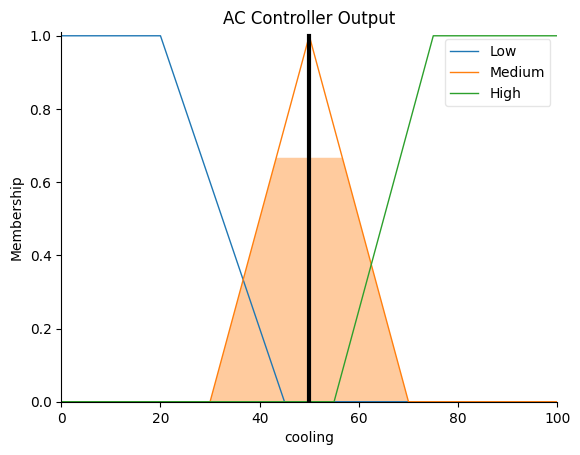


====== FUZZY AC CONTROLLER ======
1. Calculate AC Cooling
2. Temperature Membership Functions
3. Humidity Membership Functions
4. Cooling Membership Functions
5. Display Fuzzy Rules
6. Exit
Enter your choice (1-6): 2


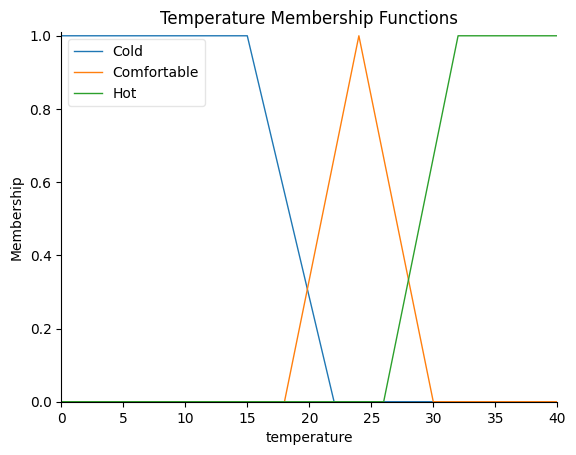


====== FUZZY AC CONTROLLER ======
1. Calculate AC Cooling
2. Temperature Membership Functions
3. Humidity Membership Functions
4. Cooling Membership Functions
5. Display Fuzzy Rules
6. Exit
Enter your choice (1-6): 3


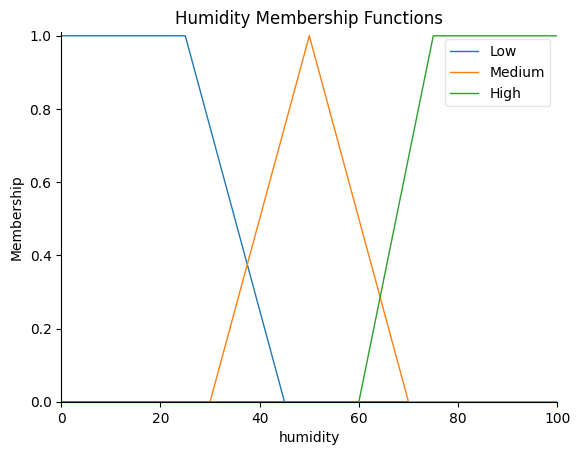


====== FUZZY AC CONTROLLER ======
1. Calculate AC Cooling
2. Temperature Membership Functions
3. Humidity Membership Functions
4. Cooling Membership Functions
5. Display Fuzzy Rules
6. Exit
Enter your choice (1-6): 4


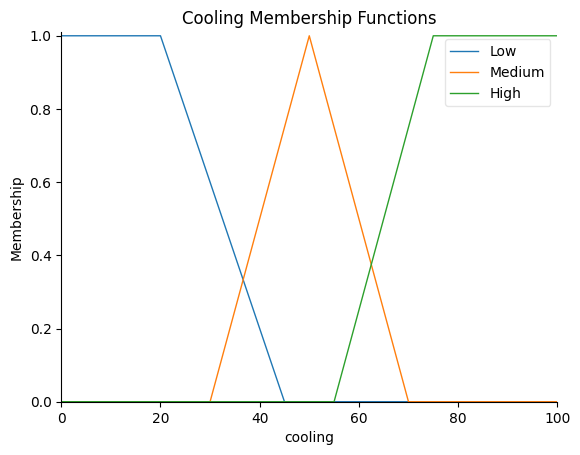


====== FUZZY AC CONTROLLER ======
1. Calculate AC Cooling
2. Temperature Membership Functions
3. Humidity Membership Functions
4. Cooling Membership Functions
5. Display Fuzzy Rules
6. Exit
Enter your choice (1-6): 5

========== FUZZY RULES ==========
Rule 1: IF temperature[Cold] AND humidity[Low] THEN cooling[Low]
	AND aggregation function : fmin
	OR aggregation function  : fmax
Rule 2: IF temperature[Cold] AND humidity[Medium] THEN cooling[Low]
	AND aggregation function : fmin
	OR aggregation function  : fmax
Rule 3: IF temperature[Cold] AND humidity[High] THEN cooling[Low]
	AND aggregation function : fmin
	OR aggregation function  : fmax
Rule 4: IF temperature[Comfortable] AND humidity[Low] THEN cooling[Low]
	AND aggregation function : fmin
	OR aggregation function  : fmax
Rule 5: IF temperature[Comfortable] AND humidity[Medium] THEN cooling[Medium]
	AND aggregation function : fmin
	OR aggregation function  : fmax
Rule 6: IF temperature[Comfortable] AND humidity[High] THEN cooling[

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# 1. Define input and output variables
temperature = ctrl.Antecedent(np.arange(0, 41, 1), 'temperature')
humidity = ctrl.Antecedent(np.arange(0, 101, 1), 'humidity')
cooling = ctrl.Consequent(np.arange(0, 101, 1), 'cooling')

# 2. Define membership functions
temperature['Cold'] = fuzz.trapmf(temperature.universe, [0, 0, 15, 22])
temperature['Comfortable'] = fuzz.trimf(temperature.universe, [18, 24, 30])
temperature['Hot'] = fuzz.trapmf(temperature.universe, [26, 32, 40, 40])

humidity['Low'] = fuzz.trapmf(humidity.universe, [0, 0, 25, 45])
humidity['Medium'] = fuzz.trimf(humidity.universe, [30, 50, 70])
humidity['High'] = fuzz.trapmf(humidity.universe, [60, 75, 100, 100])

cooling['Low'] = fuzz.trapmf(cooling.universe, [0, 0, 20, 45])
cooling['Medium'] = fuzz.trimf(cooling.universe, [30, 50, 70])
cooling['High'] = fuzz.trapmf(cooling.universe, [55, 75, 100, 100])

# 3. Define fuzzy rules
rules = [
    ctrl.Rule(temperature['Cold'] & humidity['Low'], cooling['Low']),
    ctrl.Rule(temperature['Cold'] & humidity['Medium'], cooling['Low']),
    ctrl.Rule(temperature['Cold'] & humidity['High'], cooling['Low']),

    ctrl.Rule(temperature['Comfortable'] & humidity['Low'], cooling['Low']),
    ctrl.Rule(temperature['Comfortable'] & humidity['Medium'], cooling['Medium']),
    ctrl.Rule(temperature['Comfortable'] & humidity['High'], cooling['Medium']),

    ctrl.Rule(temperature['Hot'] & humidity['Low'], cooling['Medium']),
    ctrl.Rule(temperature['Hot'] & humidity['Medium'], cooling['High']),
    ctrl.Rule(temperature['Hot'] & humidity['High'], cooling['High'])
]

# 4. Create control system
ac_system = ctrl.ControlSystem(rules)

# 5. Calculate cooling output
def calculate_cooling(temp, hum):
    sim = ctrl.ControlSystemSimulation(ac_system)
    sim.input['temperature'] = temp
    sim.input['humidity'] = hum
    sim.compute()

    print("\nFinal Cooling Level:", round(sim.output['cooling'], 2), "%")

    result = sim.output['cooling']
    if result < 40:
        print("AC Status: LOW COOLING")
    elif result < 70:
        print("AC Status: MEDIUM COOLING")
    else:
        print("AC Status: HIGH COOLING")

    cooling.view(sim=sim)
    plt.title("AC Controller Output")
    plt.show()

# 6. Display membership functions
def plot_membership(variable, title):
    variable.view()
    plt.title(title)
    plt.show()

# 7. Display fuzzy rules
def display_rules():
    print("\n========== FUZZY RULES ==========")
    for i, rule in enumerate(rules, 1):
        print(f"Rule {i}: {rule}")

# 8. Main menu
while True:
    print("\n====== FUZZY AC CONTROLLER ======")
    print("1. Calculate AC Cooling")
    print("2. Temperature Membership Functions")
    print("3. Humidity Membership Functions")
    print("4. Cooling Membership Functions")
    print("5. Display Fuzzy Rules")
    print("6. Exit")

    choice = input("Enter your choice (1-6): ")

    if choice == '1':
        try:
            temp = float(input("Enter Temperature (0-40 °C): "))
            hum = float(input("Enter Humidity (0-100%): "))

            if 0 <= temp <= 40 and 0 <= hum <= 100:
                calculate_cooling(temp, hum)
            else:
                print("Values are outside the allowed range.")

        except ValueError:
            print("Please enter valid numerical values.")

    elif choice == '2':
        plot_membership(temperature, "Temperature Membership Functions")

    elif choice == '3':
        plot_membership(humidity, "Humidity Membership Functions")

    elif choice == '4':
        plot_membership(cooling, "Cooling Membership Functions")

    elif choice == '5':
        display_rules()

    elif choice == '6':
        print("Exiting AC Controller. Thank you!")
        break

    else:
        print("Invalid choice! Select between 1 and 6.")
